# Le mie partite dell'Inter a San Siro
Statistiche sulle partite viste dal vivo, a partire da `presenze_stadio.csv`.

Esegui le celle in ordine (Kernel → Restart & Run All). Se il CSV è in un'altra cartella, cambia `CSV_PATH` nella prima cella.

In [38]:
import re
import pandas as pd
import matplotlib.pyplot as plt

CSV_PATH = "presenze_stadio.csv"
MIN_PARTITE = 3   # soglia minima di partite per le classifiche con percentuali (arbitri)

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 180)
plt.rcParams["figure.figsize"] = (9, 4)
COL = {"V": "#2e7d32", "N": "#9e9e9e", "P": "#c62828"}

## 1. Caricamento e preparazione

In [39]:
df = pd.read_csv(CSV_PATH)
df["data"] = pd.to_datetime(df["data"], errors="coerce")
df = df.sort_values("data").reset_index(drop=True)

df["inter_in_casa"] = df["inter_in_casa"].astype(str).str.strip().str.lower().eq("true")
for c in ["gol_inter", "gol_avversario", "presenze"]:
    df[c] = pd.to_numeric(df[c], errors="coerce")

# se manca l'esito lo ricalcolo dai gol
mancanti = df["esito_inter"].isna() & df["gol_inter"].notna()
if mancanti.any():
    df.loc[mancanti, "esito_inter"] = df.loc[mancanti].apply(
        lambda r: "V" if r.gol_inter > r.gol_avversario
        else ("N" if r.gol_inter == r.gol_avversario else "P"), axis=1)

df["diff_reti"] = df["gol_inter"] - df["gol_avversario"]
df["risultato"] = df.apply(
    lambda r: f"Inter {int(r.gol_inter)}-{int(r.gol_avversario)} {r.avversario}"
    if pd.notna(r.gol_inter) else str(r.avversario), axis=1)

print(f"{len(df)} partite, dal {df['data'].min():%d/%m/%Y} al {df['data'].max():%d/%m/%Y}")
df[["data", "competizione", "turno", "risultato", "esito_inter"]].tail()

76 partite, dal 19/08/2007 al 25/10/2026


,data,competizione,turno,risultato,esito_inter
71,2026-09-14,Serie A,4,Inter 5-3 Udinese,V
72,2026-10-10,Serie A,6,Inter 3-0 Parma,V
73,2026-10-13,Champions League,2,Inter 3-4 Club Brugge,P
74,2026-10-21,Champions League,3,Inter 1-0 Shakhtar Donetsk,V
75,2026-10-25,Serie A,8,Inter 2-1 Fiorentina,V


### Marcatori, ammoniti ed espulsi in formato "una riga per evento"
Le colonne di testo (`"Milito 24'; Mariga 35'"`) vengono spezzate in una tabella `eventi`.

In [40]:
def parse_eventi(s):
    # "Milito 24'; Icardi 6' (rig.)" -> lista di dict
    if not isinstance(s, str) or not s.strip():
        return []
    out = []
    for parte in s.split(";"):
        parte = parte.strip()
        if not parte:
            continue
        m = re.match(r"^(.*?)\s+(\d+)(?:\+(\d+))?'\s*(?:\(([^)]*)\))?$", parte)
        if m:
            giocatore, minuto, extra, nota = m.groups()
            out.append({"giocatore": giocatore.strip(), "minuto": int(minuto),
                        "extra": int(extra) if extra else 0, "nota": nota or ""})
        else:
            out.append({"giocatore": parte, "minuto": None, "extra": 0, "nota": ""})
    return out


TIPI = {"marcatori": "gol", "ammoniti": "ammonizione", "espulsi": "espulsione"}
righe = []
for pid, r in df.iterrows():
    for prefisso, tipo in TIPI.items():
        for lato in ("casa", "trasferta"):
            colonna = f"{prefisso}_{lato}"
            if colonna not in df.columns:
                continue
            for e in parse_eventi(r[colonna]):
                dell_inter = (lato == "casa") == bool(r["inter_in_casa"])
                righe.append({"partita_id": pid, "tipo": tipo,
                              "squadra": "Inter" if dell_inter else "Avversario", **e})

COLONNE = ["partita_id", "tipo", "squadra", "giocatore", "minuto", "extra", "nota"]
eventi = pd.DataFrame(righe, columns=COLONNE)
eventi["minuto"] = pd.to_numeric(eventi["minuto"], errors="coerce")
# 45+2 resta nel primo tempo, 90+3 diventa 91 (fascia "90+")
eventi["minuto_eff"] = eventi["minuto"] + ((eventi["minuto"] >= 90) & (eventi["extra"] > 0)).astype(int)

info = df[["data", "stagione", "competizione", "avversario"]].copy()
info.index.name = "partita_id"
eventi = eventi.merge(info.reset_index(), on="partita_id", how="left")

print(f"{len(eventi)} eventi: ", eventi["tipo"].value_counts().to_dict())
eventi.head()

501 eventi:  {'ammonizione': 250, 'gol': 243, 'espulsione': 8}


,partita_id,tipo,squadra,giocatore,minuto,extra,nota,minuto_eff,data,stagione,competizione,avversario
0,0,gol,Avversario,De Rossi,78.0,0,rig.,78.0,2007-08-19,2007-2008,Supercoppa Italiana,Roma
1,0,ammonizione,Inter,Marco Materazzi,NaN,0,,NaN,2007-08-19,2007-2008,Supercoppa Italiana,Roma
2,0,ammonizione,Inter,Dejan Stanković,NaN,0,,NaN,2007-08-19,2007-2008,Supercoppa Italiana,Roma
3,0,ammonizione,Inter,Zlatan Ibrahimović,NaN,0,,NaN,2007-08-19,2007-2008,Supercoppa Italiana,Roma
4,0,ammonizione,Avversario,Doni,NaN,0,,NaN,2007-08-19,2007-2008,Supercoppa Italiana,Roma


### Controllo qualità
Confronto i gol del punteggio con i marcatori trovati. Le righe qui sotto sono partite in cui non coincidono
(marcatori mancanti su Wikipedia, formato diverso...): vale la pena guardarle a mano.

In [41]:
gol_ev = eventi[eventi["tipo"] == "gol"]
df["gol_inter_marcatori"] = gol_ev[gol_ev["squadra"] == "Inter"].groupby("partita_id").size().reindex(df.index).fillna(0).astype(int)
df["gol_avv_marcatori"] = gol_ev[gol_ev["squadra"] == "Avversario"].groupby("partita_id").size().reindex(df.index).fillna(0).astype(int)

incoerenti = df[(df["gol_inter"] != df["gol_inter_marcatori"]) | (df["gol_avversario"] != df["gol_avv_marcatori"])]
print(f"Partite con marcatori incoerenti col punteggio: {len(incoerenti)} su {len(df)}")
incoerenti[["data", "competizione", "risultato", "gol_inter_marcatori", "gol_avv_marcatori",
            "marcatori_casa", "marcatori_trasferta"]]

Partite con marcatori incoerenti col punteggio: 0 su 76


,data,competizione,risultato,gol_inter_marcatori,gol_avv_marcatori,marcatori_casa,marcatori_trasferta


## 2. Riepilogo generale

Partite viste                   76
Stagioni diverse                13
Avversari diversi               35
Vittorie                        59
Pareggi                          6
Sconfitte                       11
% vittorie                    77.6
Gol fatti                      180
Gol subiti                      63
Media gol fatti a partita     2.37
Media gol subiti a partita    0.83
Partite senza subire gol        36


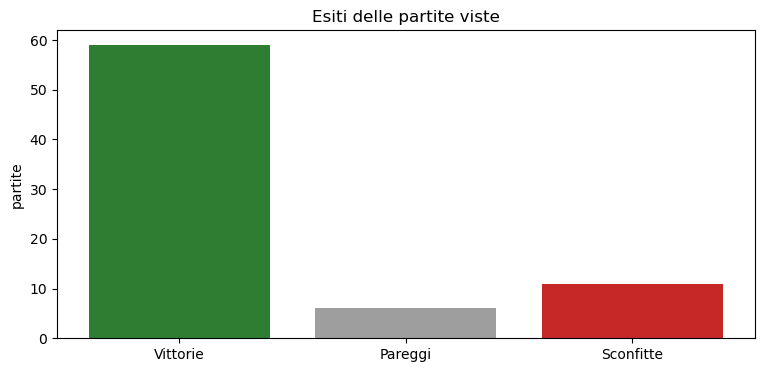

In [42]:
n = len(df)
vit, par, sco = (df["esito_inter"] == v for v in ("V", "N", "P"))
riepilogo = pd.Series({
    "Partite viste": n,
    "Stagioni diverse": df["stagione"].nunique(),
    "Avversari diversi": df["avversario"].nunique(),
    "Vittorie": int(vit.sum()),
    "Pareggi": int(par.sum()),
    "Sconfitte": int(sco.sum()),
    "% vittorie": round(100 * vit.sum() / n, 1),
    "Gol fatti": int(df["gol_inter"].sum()),
    "Gol subiti": int(df["gol_avversario"].sum()),
    "Media gol fatti a partita": round(df["gol_inter"].mean(), 2),
    "Media gol subiti a partita": round(df["gol_avversario"].mean(), 2),
    "Partite senza subire gol": int((df["gol_avversario"] == 0).sum()),
}, dtype=object)
print(riepilogo.to_string())

plt.bar(["Vittorie", "Pareggi", "Sconfitte"], [vit.sum(), par.sum(), sco.sum()],
        color=[COL["V"], COL["N"], COL["P"]])
plt.title("Esiti delle partite viste")
plt.ylabel("partite")
plt.show()

## 3. Per competizione, stagione e tipo di partita

,partite,V,N,P,GF,GS,%V,DR
competizione,,,,,,,,
Serie A,55,45,4,6,141,41,81.8,100
Champions League,10,7,0,3,18,10,70.0,8
Coppa Italia,5,5,0,0,10,3,100.0,7
Europa League,3,1,1,1,6,5,33.3,1
Supercoppa Italiana,2,1,0,1,3,2,50.0,1
Amichevoli,1,0,1,0,2,2,0.0,0


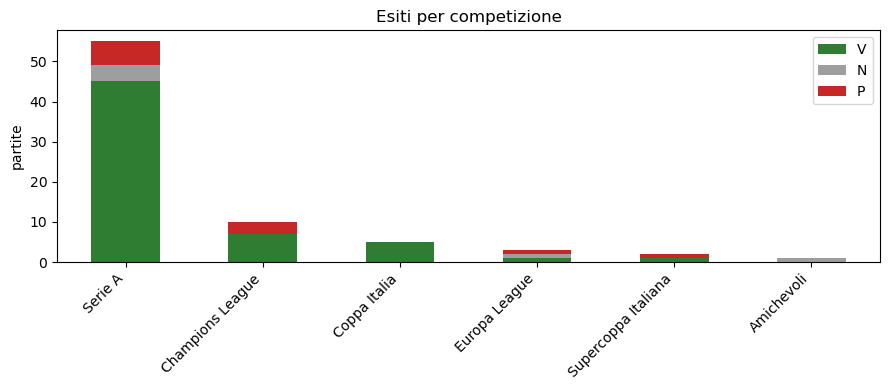

In [43]:
def tabella(colonna):
    g = df.groupby(colonna)
    t = g.agg(partite=("esito_inter", "size"),
              V=("esito_inter", lambda s: (s == "V").sum()),
              N=("esito_inter", lambda s: (s == "N").sum()),
              P=("esito_inter", lambda s: (s == "P").sum()),
              GF=("gol_inter", "sum"), GS=("gol_avversario", "sum"))
    t["%V"] = (100 * t["V"] / t["partite"]).round(1)
    t["DR"] = t["GF"] - t["GS"]
    t[["GF", "GS", "DR"]] = t[["GF", "GS", "DR"]].fillna(0).astype(int)
    return t


def barre_esiti(t, titolo):
    ax = t[["V", "N", "P"]].plot(kind="bar", stacked=True, color=[COL["V"], COL["N"], COL["P"]])
    ax.set_title(titolo)
    ax.set_xlabel("")
    ax.set_ylabel("partite")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()


tc = tabella("competizione").sort_values("partite", ascending=False)
display(tc)
barre_esiti(tc, "Esiti per competizione")

,partite,V,N,P,GF,GS,%V,DR
stagione,,,,,,,,
2007-2008,1,0,0,1,0,1,0.0,-1
2009-2010,1,1,0,0,3,1,100.0,2
2010-2011,1,1,0,0,3,1,100.0,2
2011-2012,1,0,0,1,1,2,0.0,-1
2012-2013,5,2,1,2,8,7,40.0,1
2017-2018,3,2,0,1,8,2,66.7,6
2019-2020,1,1,0,0,2,1,100.0,1
2021-2022,14,11,2,1,38,8,78.6,30
2022-2023,21,17,0,4,45,15,81.0,30


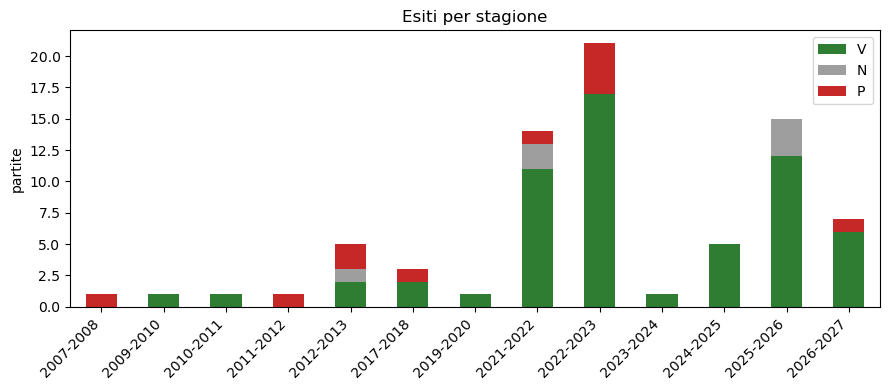

Stagione con più partite viste: 2022-2023 (21)


In [44]:
ts = tabella("stagione").sort_index()
display(ts)
barre_esiti(ts, "Esiti per stagione")
print("Stagione con più partite viste:", ts["partite"].idxmax(), f"({ts['partite'].max()})")

In [45]:
th = tabella("inter_in_casa")
th.index = th.index.map({True: "Inter in casa", False: "Inter ospite (es. derby con Milan di casa)"})
th

,partite,V,N,P,GF,GS,%V,DR
inter_in_casa,,,,,,,,
Inter ospite (es. derby con Milan di casa),2,0,1,1,4,5,0.0,-1
Inter in casa,74,59,5,10,176,58,79.7,118


## 4. Avversari e derby

In [46]:
avv = tabella("avversario").sort_values(["partite", "V"], ascending=False)
display(avv.head(15))

,partite,V,N,P,GF,GS,%V,DR
avversario,,,,,,,,
Fiorentina,6,5,1,0,13,4,83.3,9
Roma,5,3,0,2,11,6,60.0,5
Udinese,4,4,0,0,12,4,100.0,8
Hellas Verona,4,3,1,0,5,1,75.0,4
Monza,4,2,1,1,8,4,50.0,4
Atalanta,3,3,0,0,7,3,100.0,4
Cagliari,3,3,0,0,11,0,100.0,11
Genoa,3,3,0,0,7,0,100.0,7
Lecce,3,3,0,0,5,0,100.0,5


In [47]:
derby = df[df["avversario"].str.contains("Milan", case=False, na=False)]
print(f"Derby visti: {len(derby)}  ->  {derby['esito_inter'].value_counts().to_dict()}")
derby[["data", "competizione", "turno", "risultato", "esito_inter", "inter_in_casa"]]

Derby visti: 3  ->  {'V': 2, 'P': 1}


,data,competizione,turno,risultato,esito_inter,inter_in_casa
29,2022-09-03,Serie A,5,Inter 2-3 Milan,P,False
39,2023-02-05,Serie A,21,Inter 1-0 Milan,V,True
46,2023-05-16,Champions League,Second leg,Inter 1-0 Milan,V,True


## 5. Marcatori
Gli autogol (`aut.`) sono esclusi dalle classifiche dei marcatori (il nome è quello di chi li ha subiti) e hanno una tabella dedicata.

,gol,rigori,partite
giocatore,,,
L. Martínez,35,1,26
Džeko,16,0,12
Çalhanoğlu,14,6,12
Barella,10,0,10
Thuram,9,0,8
Dimarco,6,0,5
Esposito,6,0,6
Correa,5,0,4
Lukaku,5,1,4


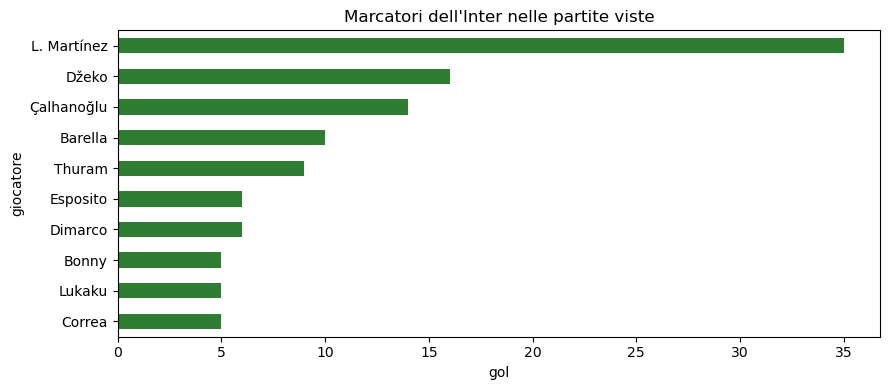

In [48]:
gol = eventi[eventi["tipo"] == "gol"]
gol_inter = gol[(gol["squadra"] == "Inter") & (gol["nota"] != "aut.")]

top = (gol_inter.groupby("giocatore")
       .agg(gol=("giocatore", "size"),
            rigori=("nota", lambda s: (s == "rig.").sum()),
            partite=("partita_id", "nunique"))
       .sort_values(["gol", "partite"], ascending=[False, True]))
display(top.head(15))

top.head(10)["gol"].sort_values().plot(kind="barh", color=COL["V"])
plt.title("Marcatori dell'Inter nelle partite viste")
plt.xlabel("gol")
plt.tight_layout()
plt.show()

In [49]:
# Doppiette, triplette, ecc.
per_partita = gol_inter.groupby(["partita_id", "giocatore"]).size().reset_index(name="gol")
multi = per_partita[per_partita["gol"] >= 2].merge(info.reset_index(), on="partita_id")
multi.sort_values(["gol", "data"], ascending=[False, True])[["data", "competizione", "avversario", "giocatore", "gol"]]

,data,competizione,avversario,giocatore,gol
7,2022-03-04,Serie A,Salernitana,L. Martínez,3
0,2010-08-21,Supercoppa Italiana,Roma,Eto'o,2
1,2017-08-20,Serie A,Fiorentina,Icardi,2
2,2021-09-18,Serie A,Bologna,Džeko,2
3,2021-10-31,Serie A,Udinese,Correa,2
4,2021-11-24,Champions League,Shakhtar Donetsk,Džeko,2
5,2021-12-12,Serie A,Cagliari,L. Martínez,2
6,2022-03-04,Serie A,Salernitana,Džeko,2
8,2022-05-06,Serie A,Empoli,L. Martínez,2
9,2022-10-26,Champions League,Viktoria Plzeň,Džeko,2


In [50]:
# Chi ha segnato di più contro l'Inter
gol_avv = gol[(gol["squadra"] == "Avversario") & (gol["nota"] != "aut.")]
(gol_avv.groupby("giocatore").size().sort_values(ascending=False).head(10)
 .rename("gol contro l'Inter").to_frame())

,gol contro l'Inter
giocatore,
Tresoldi,3
Dybala,2
Leão,2
Varela,2
McTominay,2
Moreo,2
Politano,2
Abankwah,1
Mancini,1


In [51]:
# Autogol. Su Wikipedia sono elencati sotto la squadra che ne beneficia, col nome del giocatore che li ha fatti:
# "squadra = Inter" = autogol di un avversario a favore dell'Inter, "squadra = Avversario" = autogol di un nerazzurro.
aut = gol[gol["nota"] == "aut."].copy()
aut["a favore di"] = aut["squadra"]
aut["autore"] = aut["giocatore"]
print("Autogol a favore dell'Inter:", (aut["squadra"] == "Inter").sum(),
      "| autogol dell'Inter:", (aut["squadra"] == "Avversario").sum())
aut.sort_values("data")[["data", "competizione", "avversario", "a favore di", "autore", "minuto"]]

Autogol a favore dell'Inter: 7 | autogol dell'Inter: 1


,data,competizione,avversario,a favore di,autore,minuto
71,2013-03-14,Europa League,Tottenham Hotspur,Inter,Gallas,75.0
172,2022-05-06,Serie A,Empoli,Inter,Romagnoli,40.0
308,2023-05-13,Serie A,Sassuolo,Inter,Ruan,55.0
328,2023-05-27,Serie A,Atalanta,Avversario,Onana,90.0
338,2024-11-26,Champions League,RB Leipzig,Inter,Lukeba,27.0
356,2025-08-12,Amichevoli,Monza,Inter,Birindelli,45.0
403,2026-02-14,Serie A,Juventus,Inter,Cambiaso,17.0
442,2026-05-17,Serie A,Hellas Verona,Inter,Edmundsson,47.0


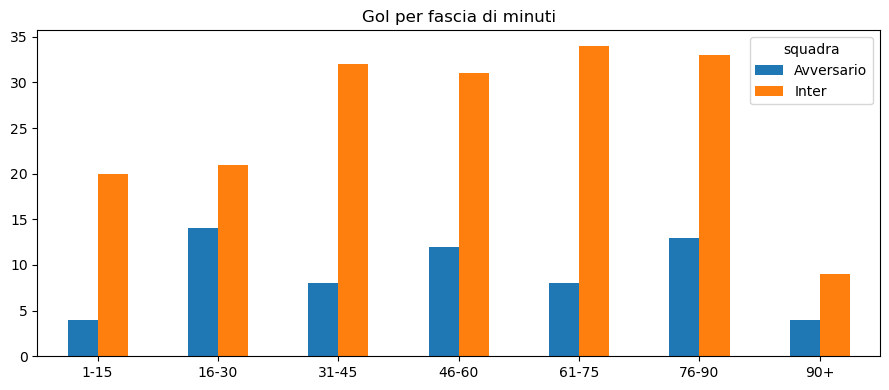

In [52]:
# In che fascia di partita arrivano i gol
ETICHETTE = ["1-15", "16-30", "31-45", "46-60", "61-75", "76-90", "90+"]
g = gol.copy()   # autogol inclusi: contano per la squadra a cui vengono assegnati
g["fascia"] = pd.cut(g["minuto_eff"], bins=[0, 15, 30, 45, 60, 75, 90, 200], labels=ETICHETTE)
fasce = (g.pivot_table(index="fascia", columns="squadra", values="partita_id",
                       aggfunc="count", observed=False)
         .reindex(ETICHETTE).fillna(0).astype(int))
fasce.plot(kind="bar")
plt.title("Gol per fascia di minuti")
plt.xlabel("")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 6. Ammoniti ed espulsi

In [53]:
amm = eventi[eventi["tipo"] == "ammonizione"]
print("Ammonizioni totali:", amm.groupby("squadra").size().to_dict())
print(f"Media ammoniti a partita: Inter {len(amm[amm.squadra == 'Inter']) / len(df):.2f}, "
      f"avversari {len(amm[amm.squadra == 'Avversario']) / len(df):.2f}")
(amm[amm["squadra"] == "Inter"].groupby("giocatore").size()
 .sort_values(ascending=False).head(10).rename("ammonizioni").to_frame())

Ammonizioni totali: {'Avversario': 156, 'Inter': 94}
Media ammoniti a partita: Inter 1.24, avversari 2.05


,ammonizioni
giocatore,
L. Martínez,10
Barella,8
Brozović,8
Bastoni,6
Çalhanoğlu,4
Dumfries,4
Mkhitaryan,4
Samuel,3
D'Ambrosio,3


In [54]:
esp = eventi[eventi["tipo"] == "espulsione"]
print("Espulsioni totali:", esp.groupby("squadra").size().to_dict())
# nota "2 gialli" = espulso per doppia ammonizione; vuota = rosso diretto
esp.sort_values("data")[["data", "stagione", "competizione", "avversario", "squadra", "giocatore", "minuto", "nota"]]

Espulsioni totali: {'Avversario': 5, 'Inter': 3}


,data,stagione,competizione,avversario,squadra,giocatore,minuto,nota
8,2007-08-19,2007-2008,Supercoppa Italiana,Roma,Avversario,Simone Perrotta,NaN,
50,2012-08-30,2012-2013,Europa League,Vaslui,Inter,Castellazzi,33.0,
63,2012-09-30,2012-2013,Serie A,Fiorentina,Avversario,Rodríguez,62.0,2 gialli
289,2023-03-19,2022-2023,Serie A,Juventus,Inter,D'Ambrosio,90.0,
290,2023-03-19,2022-2023,Serie A,Juventus,Avversario,Paredes,90.0,
369,2025-10-29,2025-2026,Serie A,Fiorentina,Avversario,Viti,86.0,2 gialli
414,2026-02-14,2025-2026,Serie A,Juventus,Avversario,Kalulu,42.0,2 gialli
496,2026-10-21,2026-2027,Champions League,Shakhtar Donetsk,Inter,Bastoni,68.0,2 gialli


## 7. Arbitri

In [55]:
arb = tabella("arbitro")
display(arb.sort_values("partite", ascending=False).head(10))

print(f"Arbitri con almeno {MIN_PARTITE} partite, per % vittorie:")
arb[arb["partite"] >= MIN_PARTITE].sort_values("%V", ascending=False)

,partite,V,N,P,GF,GS,%V,DR
arbitro,,,,,,,,
Simone Sozza,5,5,0,0,15,6,100.0,9
Gianluca Manganiello,4,4,0,0,9,2,100.0,7
Daniele Chiffi,4,1,1,2,4,5,25.0,-1
Livio Marinelli,3,3,0,0,11,1,100.0,10
Kevin Bonacina,3,2,1,0,7,2,66.7,5
Davide Massa,2,1,0,1,2,2,50.0,0
Maurizio Mariani,2,1,1,0,3,2,50.0,1
Matteo Marcenaro,2,2,0,0,10,4,100.0,6
Federico La Penna,2,2,0,0,8,2,100.0,6


Arbitri con almeno 3 partite, per % vittorie:


,partite,V,N,P,GF,GS,%V,DR
arbitro,,,,,,,,
Gianluca Manganiello,4,4,0,0,9,2,100.0,7
Livio Marinelli,3,3,0,0,11,1,100.0,10
Simone Sozza,5,5,0,0,15,6,100.0,9
Kevin Bonacina,3,2,1,0,7,2,66.7,5
Daniele Chiffi,4,1,1,2,4,5,25.0,-1


## 8. Presenze allo stadio, giorni e orari

Media spettatori nelle partite viste: 62.330
Più affollate:


,data,competizione,risultato,presenze
39,2023-02-05,Serie A,Inter 1-0 Milan,75584.0
46,2023-05-16,Champions League,Inter 1-0 Milan,75567.0
62,2026-02-14,Serie A,Inter 3-2 Juventus,75515.0
44,2023-04-30,Serie A,Inter 3-1 Lazio,75500.0
36,2023-01-04,Serie A,Inter 1-0 Napoli,75479.0


Meno affollate:


,data,competizione,risultato,presenze
8,2013-03-14,Europa League,Inter 4-1 Tottenham Hotspur,18241.0
3,2011-12-07,Champions League,Inter 1-2 CSKA Moscow,23295.0
13,2021-08-21,Serie A,Inter 4-0 Genoa,27402.0
19,2021-12-01,Serie A,Inter 2-0 Spezia,30076.0
20,2021-12-12,Serie A,Inter 4-0 Cagliari,33712.0


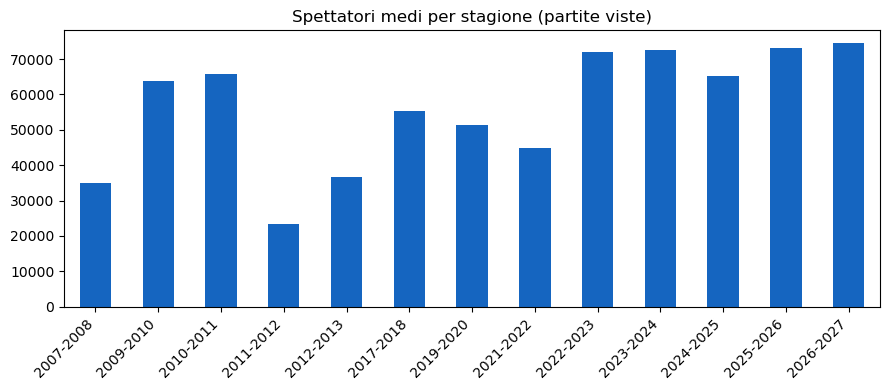

In [56]:
pres = df.dropna(subset=["presenze"])
print(f"Media spettatori nelle partite viste: {pres['presenze'].mean():,.0f}".replace(",", "."))
print("Più affollate:")
display(pres.nlargest(5, "presenze")[["data", "competizione", "risultato", "presenze"]])
print("Meno affollate:")
display(pres.nsmallest(5, "presenze")[["data", "competizione", "risultato", "presenze"]])

pres.groupby("stagione")["presenze"].mean().plot(kind="bar", color="#1565c0")
plt.title("Spettatori medi per stagione (partite viste)")
plt.xlabel("")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

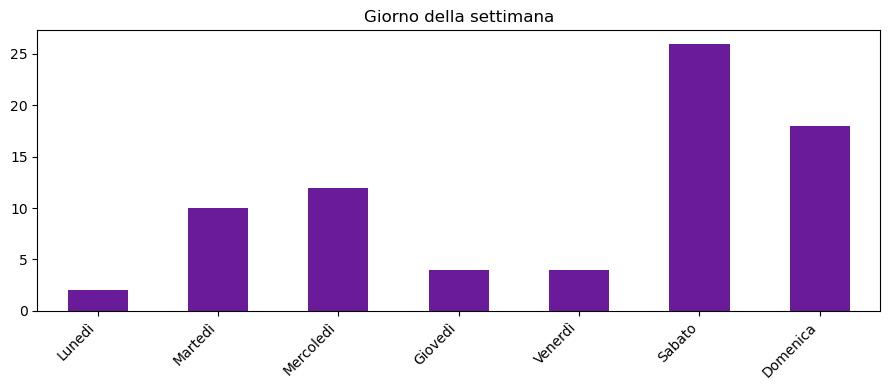

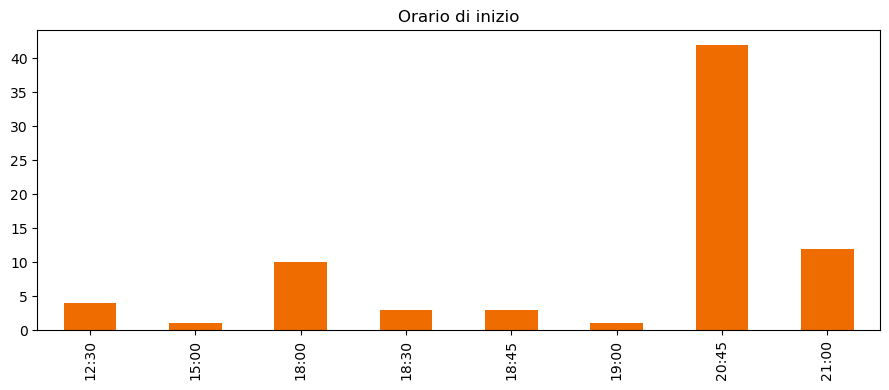

In [57]:
GIORNI = ["Lunedì", "Martedì", "Mercoledì", "Giovedì", "Venerdì", "Sabato", "Domenica"]
df["giorno"] = df["data"].dt.dayofweek.map(dict(enumerate(GIORNI)))
df["ora"] = pd.to_datetime(df["orario"], format="%H:%M", errors="coerce").dt.strftime("%H:%M")

df["giorno"].value_counts().reindex(GIORNI, fill_value=0).plot(kind="bar", color="#6a1b9a")
plt.title("Giorno della settimana")
plt.xlabel("")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

df["ora"].value_counts().sort_index().plot(kind="bar", color="#ef6c00")
plt.title("Orario di inizio")
plt.xlabel("")
plt.tight_layout()
plt.show()

## 9. Curiosità

In [58]:
colonne = ["data", "competizione", "risultato"]
print("Vittorie più larghe:")
display(df.nlargest(3, "diff_reti")[colonne])
print("Sconfitte più pesanti:")
display(df.nsmallest(3, "diff_reti")[colonne])
df["gol_totali"] = df["gol_inter"] + df["gol_avversario"]
print("Partite con più gol:")
display(df.nlargest(3, "gol_totali")[colonne])


def serie_max(esiti, valori):
    migliore = corrente = 0
    for e in esiti:
        corrente = corrente + 1 if e in valori else 0
        migliore = max(migliore, corrente)
    return migliore


print("\nSerie più lunghe tra le partite che hai visto:")
print("  vittorie consecutive:      ", serie_max(df["esito_inter"], {"V"}))
print("  partite senza sconfitte:   ", serie_max(df["esito_inter"], {"V", "N"}))
print("  partite senza vittorie:    ", serie_max(df["esito_inter"], {"N", "P"}))
print("  sconfitte consecutive:     ", serie_max(df["esito_inter"], {"P"}))

Vittorie più larghe:


,data,competizione,risultato
14,2021-09-18,Serie A,Inter 6-1 Bologna
23,2022-03-04,Serie A,Inter 5-0 Salernitana
35,2022-11-09,Serie A,Inter 6-1 Bologna


Sconfitte più pesanti:


,data,competizione,risultato
4,2012-08-09,Europa League,Inter 0-2 Hajduk Split
22,2022-02-16,Champions League,Inter 0-2 Liverpool
0,2007-08-19,Supercoppa Italiana,Inter 0-1 Roma


Partite con più gol:


,data,competizione,risultato
61,2026-01-23,Serie A,Inter 6-2 Pisa
71,2026-09-14,Serie A,Inter 5-3 Udinese
14,2021-09-18,Serie A,Inter 6-1 Bologna



Serie più lunghe tra le partite che hai visto:
  vittorie consecutive:       10
  partite senza sconfitte:    29
  partite senza vittorie:     3
  sconfitte consecutive:      2


## 10. Settori
Dove hai visto le partite. Il settore viene spezzato in **anello** (Primo/Secondo/Terzo), **colore** e **dettaglio**
(es. "laterale") quando il testo è nel formato `Terzo anello rosso`; se è scritto in un altro modo resta com'è nella colonna `anello`.

Attenzione ai campioni piccoli: con poche partite per settore le percentuali di vittoria dicono poco.

In [59]:
if "settore" not in df.columns:
    print("Colonna 'settore' assente: tutte le partite risultano 'Non indicato'.")
    df["settore"] = "Non indicato"
df["settore"] = df["settore"].fillna("").astype(str).str.strip().replace("", "Non indicato")

RE_SETTORE = re.compile(r"^(primo|secondo|terzo)\s+anello\s+(\S+)\s*(.*)$", re.I)


def spezza_settore(s):
    m = RE_SETTORE.match(s)
    if not m:
        return pd.Series({"anello": s, "colore": "n/d", "dettaglio": ""})
    return pd.Series({"anello": m.group(1).capitalize() + " anello",
                      "colore": m.group(2).lower(), "dettaglio": m.group(3).strip().lower()})


df[["anello", "colore", "dettaglio"]] = df["settore"].apply(spezza_settore)


def tabella_settore(colonna):
    t = tabella(colonna)
    t["punti/partita"] = ((3 * t["V"] + t["N"]) / t["partite"]).round(2)    # 3-1-0, anche per le coppe
    t["gol Inter/partita"] = (t["GF"] / t["partite"]).round(2)
    t["gol avv./partita"] = (t["GS"] / t["partite"]).round(2)
    return t.sort_values("partite", ascending=False)


print(f"{df['settore'].nunique()} settori diversi in {len(df)} partite")
df["settore"].value_counts().to_frame("partite")

9 settori diversi in 76 partite


,partite
settore,
Secondo anello verde,39
Terzo anello rosso,21
Primo anello arancio laterale,4
Secondo anello rosso,3
Terzo anello verde,3
Secondo anello blu,2
Primo anello arancio,2
Primo anello verde,1
Tribuna est,1


### Risultati per settore

,partite,V,N,P,GF,GS,%V,DR,punti/partita,gol Inter/partita,gol avv./partita
settore,,,,,,,,,,,
Secondo anello verde,39,31,4,4,95,28,79.5,67,2.49,2.44,0.72
Terzo anello rosso,21,17,0,4,51,19,81.0,32,2.43,2.43,0.90
Primo anello arancio laterale,4,2,0,2,5,4,50.0,1,1.50,1.25,1.00
Secondo anello rosso,3,2,0,1,7,3,66.7,4,2.00,2.33,1.00
Terzo anello verde,3,3,0,0,8,4,100.0,4,3.00,2.67,1.33
Primo anello arancio,2,2,0,0,5,1,100.0,4,3.00,2.50,0.50
Secondo anello blu,2,1,1,0,6,2,50.0,4,2.00,3.00,1.00
Primo anello verde,1,1,0,0,1,0,100.0,1,3.00,1.00,0.00
Tribuna est,1,0,1,0,2,2,0.0,0,1.00,2.00,2.00


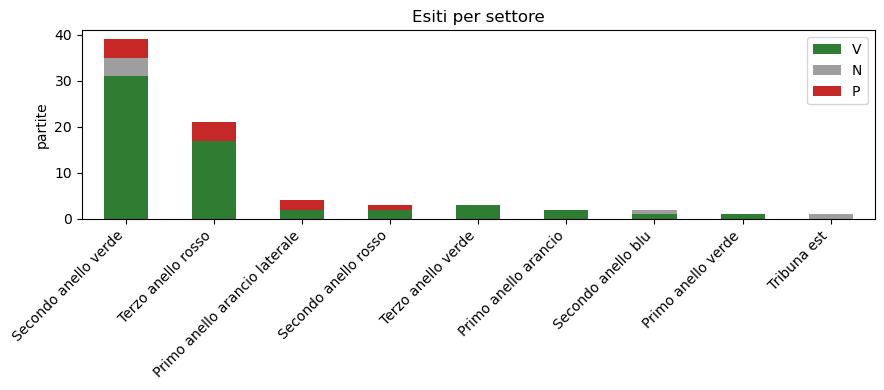

In [60]:
ts_sett = tabella_settore("settore")
display(ts_sett)
barre_esiti(ts_sett, "Esiti per settore")

In [61]:
# Il settore "fortunato" (solo settori con almeno MIN_PARTITE partite viste)
fortunati = ts_sett[ts_sett["partite"] >= MIN_PARTITE].sort_values("punti/partita", ascending=False)
print(f"Settori con almeno {MIN_PARTITE} partite, per punti a partita:")
fortunati[["partite", "V", "N", "P", "%V", "punti/partita", "gol Inter/partita", "gol avv./partita"]]

Settori con almeno 3 partite, per punti a partita:


,partite,V,N,P,%V,punti/partita,gol Inter/partita,gol avv./partita
settore,,,,,,,,
Terzo anello verde,3,3,0,0,100.0,3.00,2.67,1.33
Secondo anello verde,39,31,4,4,79.5,2.49,2.44,0.72
Terzo anello rosso,21,17,0,4,81.0,2.43,2.43,0.90
Secondo anello rosso,3,2,0,1,66.7,2.00,2.33,1.00
Primo anello arancio laterale,4,2,0,2,50.0,1.50,1.25,1.00


### Anello e colore

In [62]:
print("Per anello:")
display(tabella_settore("anello"))
print("Per colore:")
display(tabella_settore("colore"))
print("Anello × colore (numero di partite):")
pd.crosstab(df["anello"], df["colore"], margins=True, margins_name="totale")

Per anello:


,partite,V,N,P,GF,GS,%V,DR,punti/partita,gol Inter/partita,gol avv./partita
anello,,,,,,,,,,,
Secondo anello,44,34,5,5,108,33,77.3,75,2.43,2.45,0.75
Terzo anello,24,20,0,4,59,23,83.3,36,2.50,2.46,0.96
Primo anello,7,5,0,2,11,5,71.4,6,2.14,1.57,0.71
Tribuna est,1,0,1,0,2,2,0.0,0,1.00,2.00,2.00


Per colore:


,partite,V,N,P,GF,GS,%V,DR,punti/partita,gol Inter/partita,gol avv./partita
colore,,,,,,,,,,,
verde,43,35,4,4,104,32,81.4,72,2.53,2.42,0.74
rosso,24,19,0,5,58,22,79.2,36,2.38,2.42,0.92
arancio,6,4,0,2,10,5,66.7,5,2.00,1.67,0.83
blu,2,1,1,0,6,2,50.0,4,2.00,3.00,1.00
n/d,1,0,1,0,2,2,0.0,0,1.00,2.00,2.00


Anello × colore (numero di partite):


colore,arancio,blu,n/d,rosso,verde,totale
anello,,,,,,
Primo anello,6,0,0,0,1,7
Secondo anello,0,2,0,3,39,44
Terzo anello,0,0,0,21,3,24
Tribuna est,0,0,1,0,0,1
totale,6,2,1,24,43,76


### I settori nel tempo

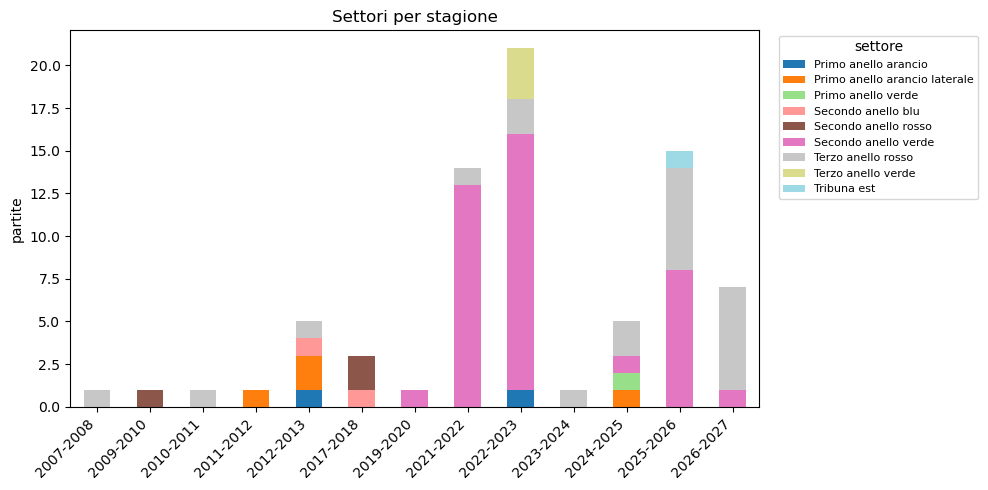

,partite,prima,ultima
settore,,,
Secondo anello verde,39,2020-01-29,2026-09-05
Terzo anello rosso,21,2007-08-19,2026-10-25
Primo anello arancio laterale,4,2011-12-07,2024-12-19
Secondo anello rosso,3,2010-04-24,2018-05-12
Terzo anello verde,3,2023-05-13,2023-05-27
Primo anello arancio,2,2013-03-14,2023-01-31
Secondo anello blu,2,2012-08-30,2018-04-17
Primo anello verde,1,2025-05-03,2025-05-03
Tribuna est,1,2025-08-12,2025-08-12


In [63]:
cross = pd.crosstab(df["stagione"], df["settore"])
ax = cross.plot(kind="bar", stacked=True, figsize=(10, 5), colormap="tab20")
ax.set_title("Settori per stagione")
ax.set_xlabel("")
ax.set_ylabel("partite")
plt.xticks(rotation=45, ha="right")
plt.legend(title="settore", bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)
plt.tight_layout()
plt.show()

(df.groupby("settore")
 .agg(partite=("data", "size"), prima=("data", "min"), ultima=("data", "max"))
 .assign(prima=lambda x: x["prima"].dt.date, ultima=lambda x: x["ultima"].dt.date)
 .sort_values("partite", ascending=False))

In [64]:
# Quante volte hai cambiato settore e le serie più lunghe nello stesso posto
blocco = (df["settore"] != df["settore"].shift()).cumsum()
print("Cambi di settore tra una partita e la successiva:", int(blocco.max()) - 1)
(df.groupby(blocco)
 .agg(settore=("settore", "first"), partite_di_fila=("data", "size"), dal=("data", "min"), al=("data", "max"))
 .assign(dal=lambda x: x["dal"].dt.date, al=lambda x: x["al"].dt.date)
 .sort_values("partite_di_fila", ascending=False).head(5).reset_index(drop=True))

Cambi di settore tra una partita e la successiva: 34


,settore,partite_di_fila,dal,al
0,Secondo anello verde,14,2020-01-29,2022-04-09
1,Secondo anello verde,11,2022-08-20,2023-01-14
2,Terzo anello rosso,5,2026-09-14,2026-10-25
3,Secondo anello verde,4,2023-02-05,2023-03-19
4,Secondo anello verde,3,2026-04-21,2026-05-17


### Competizioni, derby e affluenza per settore

In [65]:
print("Settore × competizione:")
display(pd.crosstab(df["settore"], df["competizione"], margins=True, margins_name="totale"))

df["derby"] = df["avversario"].str.contains("Milan", case=False, na=False)
print("Settore × derby:")
display(pd.crosstab(df["settore"], df["derby"].map({True: "derby", False: "altre partite"})))

print("Spettatori medi nelle partite viste da ciascun settore:")
(df.groupby("settore")["presenze"].agg(partite="size", media="mean", minimo="min", massimo="max")
 .round(0).sort_values("partite", ascending=False))

Settore × competizione:


competizione,Amichevoli,Champions League,Coppa Italia,Europa League,Serie A,Supercoppa Italiana,totale
settore,,,,,,,
Primo anello arancio,0,0,1,1,0,0,2
Primo anello arancio laterale,0,1,1,0,2,0,4
Primo anello verde,0,0,0,0,1,0,1
Secondo anello blu,0,0,0,1,1,0,2
Secondo anello rosso,0,0,0,0,3,0,3
Secondo anello verde,0,6,3,0,30,0,39
Terzo anello rosso,0,2,0,1,16,2,21
Terzo anello verde,0,1,0,0,2,0,3
Tribuna est,1,0,0,0,0,0,1


Settore × derby:


derby,altre partite,derby
settore,,
Primo anello arancio,2,0
Primo anello arancio laterale,4,0
Primo anello verde,1,0
Secondo anello blu,2,0
Secondo anello rosso,3,0
Secondo anello verde,37,2
Terzo anello rosso,21,0
Terzo anello verde,2,1
Tribuna est,1,0


Spettatori medi nelle partite viste da ciascun settore:


,partite,media,minimo,massimo
settore,,,,
Secondo anello verde,39,62249.0,27402.0,75584.0
Terzo anello rosso,21,69599.0,34898.0,75515.0
Primo anello arancio laterale,4,39312.0,23295.0,53756.0
Secondo anello rosso,3,60802.0,51752.0,66876.0
Terzo anello verde,3,73002.0,71246.0,75567.0
Primo anello arancio,2,33878.0,18241.0,49515.0
Secondo anello blu,2,44396.0,41326.0,47467.0
Primo anello verde,1,70222.0,70222.0,70222.0
Tribuna est,1,NaN,NaN,NaN


### Cosa hai visto da ogni settore

In [66]:
legame = df[["settore"]].rename_axis("partita_id").reset_index()

# marcatori dell'Inter più visti per settore (top 3)
gs = gol_inter.merge(legame, on="partita_id")
(gs.groupby(["settore", "giocatore"]).size().rename("gol").reset_index()
 .sort_values(["settore", "gol"], ascending=[True, False]).groupby("settore").head(3)
 .reset_index(drop=True))

,settore,giocatore,gol
0,Primo anello arancio,Cassano,1
1,Primo anello arancio,Darmian,1
2,Primo anello arancio,Palacio,1
3,Primo anello arancio laterale,Arnautović,1
4,Primo anello arancio laterale,Asllani,1
5,Primo anello arancio laterale,Cambiasso,1
6,Primo anello verde,Asllani,1
7,Secondo anello blu,Brozović,1
8,Secondo anello blu,Cancelo,1
9,Secondo anello blu,Guarín,1


In [67]:
# Ammonizioni ed espulsioni per partita, per settore
cart = eventi[eventi["tipo"].isin(["ammonizione", "espulsione"])].merge(legame, on="partita_id")
if len(cart):
    cs = cart.pivot_table(index="settore", columns=["tipo", "squadra"], values="partita_id",
                          aggfunc="count", fill_value=0)
    cs = cs.reindex(df["settore"].unique()).fillna(0)
    print("Cartellini per partita vista, per settore:")
    display(cs.div(df.groupby("settore").size(), axis=0).round(2))
else:
    print("Nessun cartellino trovato.")

Cartellini per partita vista, per settore:


tipo                          ammonizione       espulsione      
squadra                        Avversario Inter Avversario Inter
settore                                                         
Primo anello arancio                 3.00  2.00       0.00  0.00
Primo anello arancio laterale        2.50  2.00       0.25  0.00
Primo anello verde                   3.00  1.00       0.00  0.00
Secondo anello blu                   2.00  1.50       0.00  0.50
Secondo anello rosso                 2.00  1.33       0.00  0.00
Secondo anello verde                 2.05  1.00       0.03  0.03
Terzo anello rosso                   1.86  1.48       0.14  0.05
Terzo anello verde                   2.67  1.33       0.00  0.00
Tribuna est                          0.00  0.00       0.00  0.00

## 11. Esporta la tabella degli eventi
Utile per analisi più dettagliate o per grafici in altri strumenti.

In [68]:
eventi.to_csv("eventi_presenze.csv", index=False, encoding="utf-8-sig")
print("Salvato eventi_presenze.csv")

Salvato eventi_presenze.csv
